In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from wordcloud import WordCloud
from collections import Counter
import nltk
from nltk.corpus import stopwords

# Download stopwords jika belum ada
nltk.download('stopwords')
stop_words = set(stopwords.words('indonesian')) # Bisa diganti 'english'

# --- GENERATE DATA CONTOH ---
data_teks = [
    "Python sangat populer untuk analisis data dan kecerdasan buatan",
    "Visualisasi data membantu kita memahami informasi yang tersembunyi",
    "Belajar Python itu menyenangkan dan sangat berguna di era digital",
    "Data scientist menggunakan Python untuk mengolah data besar",
    "Analisis teks adalah bagian penting dari data science",
    "Grafik dan diagram mempermudah presentasi hasil analisis"
]

# Gabungkan semua teks menjadi satu string besar
all_text = " ".join(data_teks).lower()
# Tokenisasi sederhana (pisahkan kata dan buang stopword)
words = [word for word in all_text.split() if word not in stop_words and len(word) > 2]

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


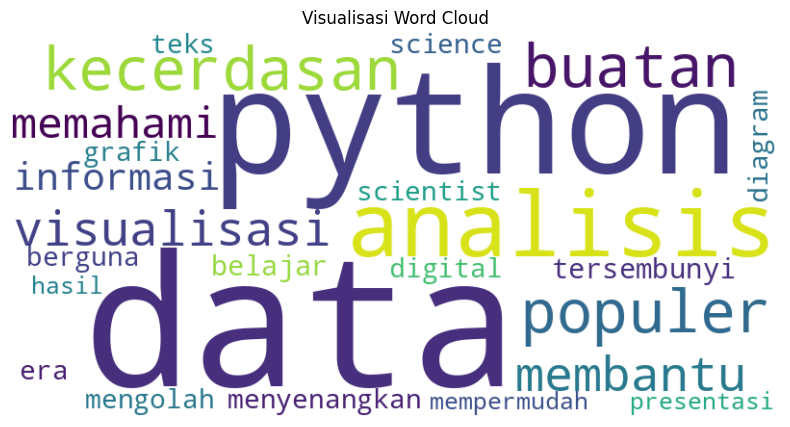

In [2]:
def plot_wordcloud(text):
    wordcloud = WordCloud(width=800, height=400, background_color='white').generate(text)
    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.axis('off')
    plt.title("Visualisasi Word Cloud")
    plt.show()

plot_wordcloud(" ".join(words))

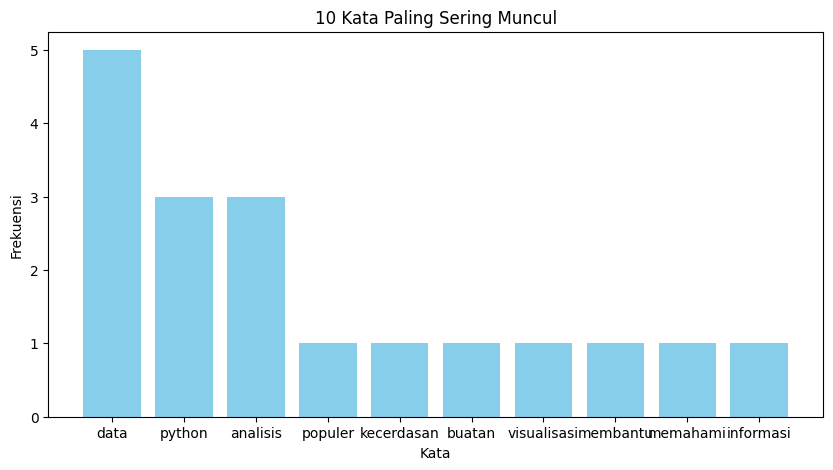

In [3]:
def plot_bar_chart(words):
    counts = Counter(words).most_common(10)
    word_labels, word_counts = zip(*counts)

    plt.figure(figsize=(10, 5))
    plt.bar(word_labels, word_counts, color='skyblue')
    plt.xlabel('Kata')
    plt.ylabel('Frekuensi')
    plt.title('10 Kata Paling Sering Muncul')
    plt.show()

plot_bar_chart(words)

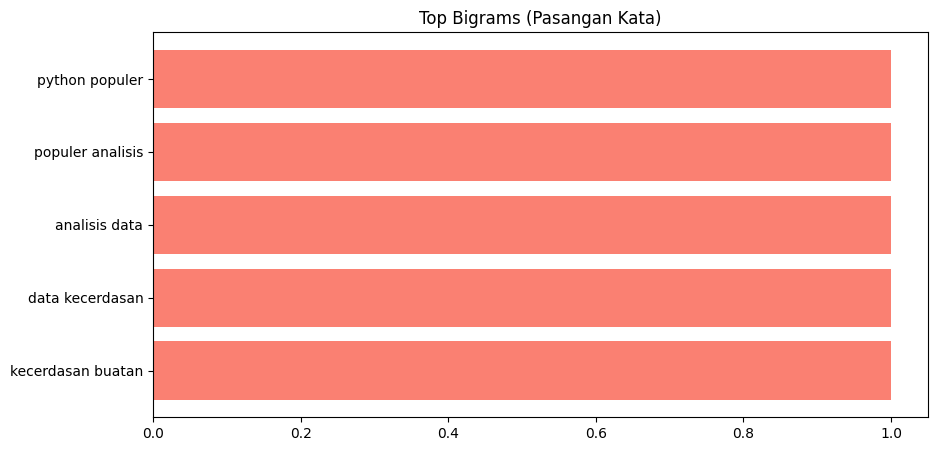

In [4]:
def plot_bigrams(words):
    bigrams = list(nltk.bigrams(words))
    bigram_counts = Counter(bigrams).most_common(5)

    # Ubah format tuple ('data', 'science') menjadi string 'data science'
    labels = [f"{b[0]} {b[1]}" for b, count in bigram_counts]
    values = [count for b, count in bigram_counts]

    plt.figure(figsize=(10, 5))
    plt.barh(labels, values, color='salmon')
    plt.gca().invert_yaxis()
    plt.title('Top Bigrams (Pasangan Kata)')
    plt.show()

plot_bigrams(words)

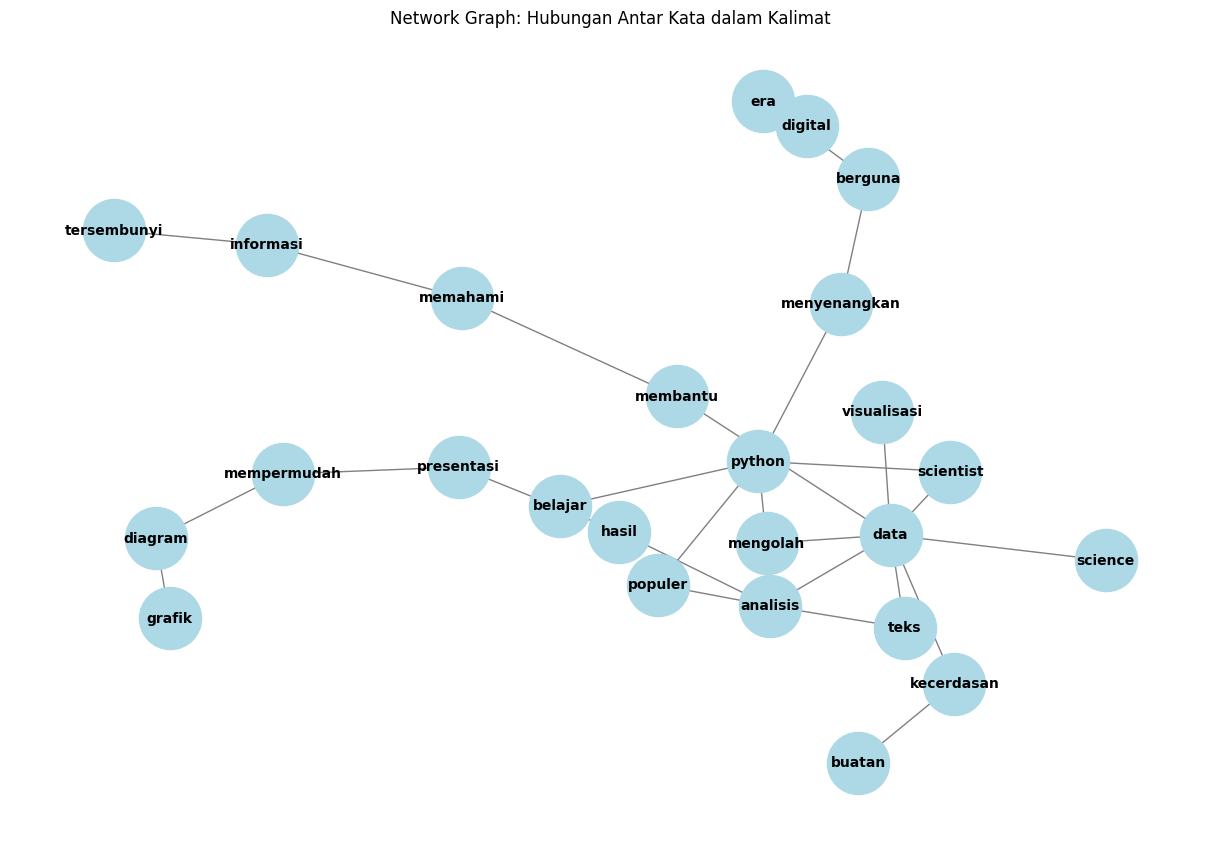

In [5]:
import networkx as nx

def plot_network_graph(data_teks, stop_words):
    G = nx.Graph()

    for kalimat in data_teks:
        # Bersihkan kata dalam setiap kalimat
        words = [w.lower() for w in kalimat.split() if w.lower() not in stop_words and len(w) > 2]

        # Buat hubungan (edge) antar kata yang bertetangga
        for i in range(len(words) - 1):
            if G.has_edge(words[i], words[i+1]):
                G[words[i]][words[i+1]]['weight'] += 1
            else:
                G.add_edge(words[i], words[i+1], weight=1)

    plt.figure(figsize=(12, 8))
    pos = nx.spring_layout(G, k=0.5) # Layout agar tidak tumpang tindih

    # Gambar node dan garis
    nx.draw(G, pos, with_labels=True,
            node_color='lightblue',
            node_size=2000,
            font_size=10,
            font_weight='bold',
            edge_color='gray')

    plt.title("Network Graph: Hubungan Antar Kata dalam Kalimat")
    plt.show()

plot_network_graph(data_teks, stop_words)